# 2 – Logistic Regression: Student Dropout Prediction

Predict a student's final status – **Dropout / Enrolled / Graduate** – from the prepared data (110 features, made by `1_data_preparation.ipynb`). This is the main model of the project and the one used in the web demo.

- Part A – 3-class model (Dropout / Enrolled / Graduate) → softmax
- Part B – Binary early-warning model (Dropout vs Graduate) → sigmoid
- Part C – Comparison of the model varieties
- Part D – Different pre-processing (same best settings, different data versions)

**Why Logistic Regression suits this problem**
- The target is a category, and the model gives a probability for every class, so each student gets a risk score.
- Its weights show which features raise or lower the risk, so the results can be explained to university staff.
- It is fast and stable on a medium-sized dataset (3,539 training students) and is a strong baseline for the other models.
- It needs scaled features, which the data preparation step already provides.

## 1. Import libraries

In [1]:
import numpy as np                # arrays and maths
import pandas as pd               # tables
import matplotlib.pyplot as plt   # plots

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold   # finds the best hyperparameters
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.preprocessing import MinMaxScaler   # used in Part D
from sklearn.decomposition import PCA            # used in Part D
import joblib                                     # save the model for the web demo

## 2. Load the preprocessed data
`X` = the 110 input features, `y` = the `target` column.

In [2]:
train = pd.read_csv("data/processed/train.csv")
test = pd.read_csv("data/processed/test.csv")

X_train = train.drop(columns="target")
y_train = train["target"]
X_test = test.drop(columns="target")
y_test = test["target"]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(y_train.value_counts())

Train: (3539, 110) | Test: (885, 110)
target
Graduate    1767
Dropout     1137
Enrolled     635
Name: count, dtype: int64


# Part A – 3-class model (Dropout / Enrolled / Graduate)
With 3 classes, LogisticRegression uses softmax automatically: it gives one probability per class, and they add up to 1.

## A1. Baseline model (default settings, no tuning)

In [3]:
base = LogisticRegression(max_iter=1000, random_state=42)
base.fit(X_train, y_train)
base_pred = base.predict(X_test)

print(f"Baseline macro F1: {f1_score(y_test, base_pred, average='macro'):.4f}")
print(classification_report(y_test, base_pred))

Baseline macro F1: 0.7049
              precision    recall  f1-score   support

     Dropout       0.79      0.76      0.78       284
    Enrolled       0.57      0.41      0.47       159
    Graduate       0.82      0.92      0.87       442

    accuracy                           0.78       885
   macro avg       0.72      0.70      0.70       885
weighted avg       0.76      0.78      0.77       885



## A2. Hyperparameter tuning – GridSearchCV with Stratified 5-fold cross-validation
- C – inverse of regularisation strength 
- class_weight – how much each class's mistakes count (our classes are imbalanced)
- scoring="f1 macro" – every class counts equally, including the small Enrolled class

Only the training data is used here. The test set stays unseen until A4.

In [4]:
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced", {"Dropout": 1, "Enrolled": 1.5, "Graduate": 1}],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42),
                    param_grid, cv=cv, scoring="f1_macro")
grid.fit(X_train, y_train)

print("Models tried:", len(grid.cv_results_["params"]))
print("Best parameters:", grid.best_params_)
print(f"Best CV macro F1: {grid.best_score_:.4f}")

Models tried: 15
Best parameters: {'C': 0.1, 'class_weight': {'Dropout': 1, 'Enrolled': 1.5, 'Graduate': 1}}
Best CV macro F1: 0.7174


## A3. All models tried and their cross-validation scores

In [5]:
results = pd.DataFrame(grid.cv_results_)
results[["param_C", "param_class_weight", "mean_test_score", "rank_test_score"]].sort_values("rank_test_score")

,param_C,param_class_weight,mean_test_score,rank_test_score
5,0.10,"{'Dropout': 1, 'Enrolled': 1.5, 'Graduate': 1}",0.717432,1
4,0.10,balanced,0.716536,2
13,100.00,balanced,0.711426,3
7,1.00,balanced,0.710775,4
8,1.00,"{'Dropout': 1, 'Enrolled': 1.5, 'Graduate': 1}",0.710387,5
10,10.00,balanced,0.709554,6
14,100.00,"{'Dropout': 1, 'Enrolled': 1.5, 'Graduate': 1}",0.708554,7
11,10.00,"{'Dropout': 1, 'Enrolled': 1.5, 'Graduate': 1}",0.706237,8
1,0.01,balanced,0.703079,9
12,100.00,None,0.702391,10


## A4. Evaluate the best model on the test set (unseen data)

Accuracy : 0.7627
Macro F1 : 0.7067
ROC AUC  : 0.8881
              precision    recall  f1-score   support

     Dropout       0.82      0.69      0.75       284
    Enrolled       0.49      0.53      0.51       159
    Graduate       0.83      0.89      0.86       442

    accuracy                           0.76       885
   macro avg       0.71      0.70      0.71       885
weighted avg       0.77      0.76      0.76       885



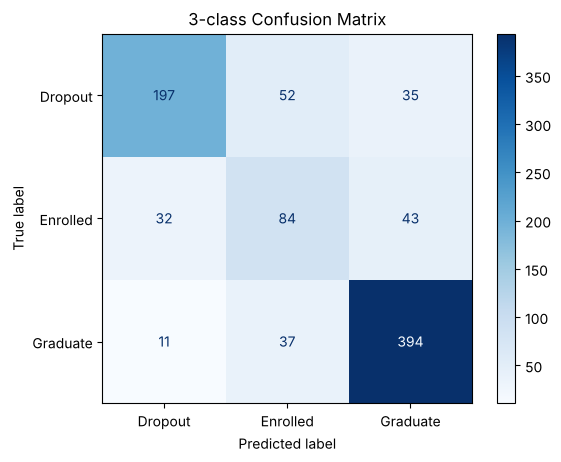

In [6]:
model = grid.best_estimator_
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1 : {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_prob, multi_class='ovr'):.4f}")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap="Blues")
plt.title("3-class Confusion Matrix")
plt.show()

## A5. Overfitting check – train F1 vs test F1
A small gap means the model works as well on new students as on the students it learned from.

In [7]:
train_f1 = f1_score(y_train, model.predict(X_train), average="macro")
test_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Train F1: {train_f1:.4f} | Test F1: {test_f1:.4f} | Gap: {train_f1 - test_f1:.4f}")

Train F1: 0.7461 | Test F1: 0.7067 | Gap: 0.0394


## A6. Predict one student – softmax probabilities
`decision_function` gives one score z per class; softmax turns the scores into probabilities.

In [8]:
student = X_test.iloc[[0]]
print("Actual   :", y_test.iloc[0])
print("Predicted:", model.predict(student)[0])
print(pd.Series(model.predict_proba(student)[0], index=model.classes_).round(3))

z = model.decision_function(student)[0]
print("Softmax by hand:", (np.exp(z) / np.exp(z).sum()).round(3))

Actual   : Graduate
Predicted: Graduate
Dropout     0.021
Enrolled    0.136
Graduate    0.843
dtype: float64
Softmax by hand: [0.021 0.136 0.843]


# Part B – Binary model (Dropout vs Graduate)
Same steps as Part A. Only these things change:
1. Enrolled rows are removed, and the target becomes Dropout = 1, Graduate = 0
2. The model uses sigmoid
3. Scoring is the F1 of the Dropout class

## B1. Prepare the binary data

In [9]:
train_b = train[train["target"] != "Enrolled"]
test_b = test[test["target"] != "Enrolled"]

Xb_train = train_b.drop(columns="target")
yb_train = (train_b["target"] == "Dropout").astype(int)   # Dropout = 1, Graduate = 0
Xb_test = test_b.drop(columns="target")
yb_test = (test_b["target"] == "Dropout").astype(int)

print("Train:", Xb_train.shape, "| Test:", Xb_test.shape)
print(yb_train.value_counts())

Train: (2904, 110) | Test: (726, 110)
target
0    1767
1    1137
Name: count, dtype: int64


## B2. Hyperparameter tuning – GridSearchCV (same CV as Part A)

In [10]:
param_grid_b = {"C": [0.01, 0.1, 1, 10, 100], "class_weight": [None, "balanced"]}   # C = inverse of regularisation strength
grid_b = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42),
                      param_grid_b, cv=cv, scoring="f1")
grid_b.fit(Xb_train, yb_train)

print("Models tried:", len(grid_b.cv_results_["params"]))
print("Best parameters:", grid_b.best_params_)
print(f"Best CV F1 (Dropout): {grid_b.best_score_:.4f}")   # 10 settings x 5 folds

Models tried: 10
Best parameters: {'C': 10, 'class_weight': 'balanced'}
Best CV F1 (Dropout): 0.8785


## B3. Evaluate the best binary model on the test set

Accuracy : 0.9022
Precision: 0.8845
Recall   : 0.8627
F1 Score : 0.8734
ROC AUC  : 0.9451


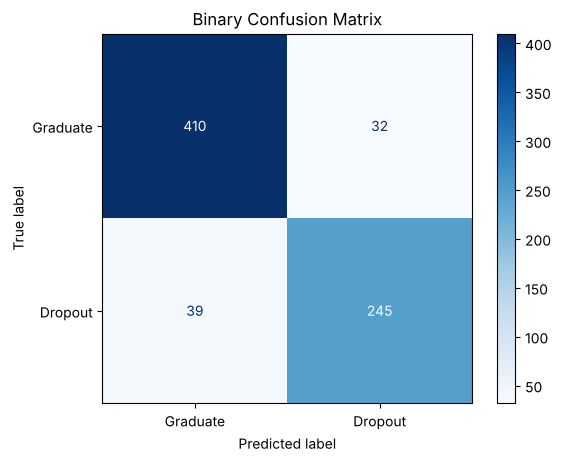

In [11]:
model_b = grid_b.best_estimator_
yb_pred = model_b.predict(Xb_test)
yb_prob = model_b.predict_proba(Xb_test)[:, 1]   # P(Dropout)

print(f"Accuracy : {accuracy_score(yb_test, yb_pred):.4f}")
print(f"Precision: {precision_score(yb_test, yb_pred):.4f}")
print(f"Recall   : {recall_score(yb_test, yb_pred):.4f}")
print(f"F1 Score : {f1_score(yb_test, yb_pred):.4f}")
print(f"ROC AUC  : {roc_auc_score(yb_test, yb_prob):.4f}")

cm_b = confusion_matrix(yb_test, yb_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_b, display_labels=["Graduate", "Dropout"])
disp.plot(cmap="Blues")
plt.title("Binary Confusion Matrix")
plt.show()

## B4. ROC curve

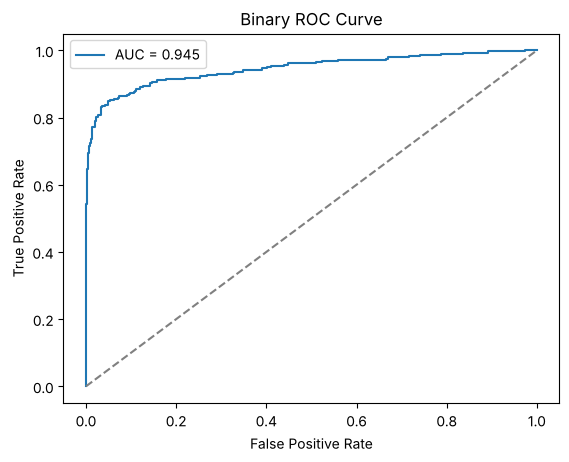

In [12]:
fpr, tpr, _ = roc_curve(yb_test, yb_prob)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(yb_test, yb_prob):.3f}")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Binary ROC Curve")
plt.legend()
plt.show()

# how well the model separates Dropout from Graduate at every threshold

## B5. Overfitting check – train F1 vs test F1

In [13]:
train_f1_b = f1_score(yb_train, model_b.predict(Xb_train))
test_f1_b = f1_score(yb_test, yb_pred)

print(f"Train F1: {train_f1_b:.4f} | Test F1: {test_f1_b:.4f} | Gap: {train_f1_b - test_f1_b:.4f}")

Train F1: 0.8980 | Test F1: 0.8734 | Gap: 0.0246


## B6. Predict one student – sigmoid and the 0.5 threshold

In [14]:
student_b = Xb_test.iloc[[0]]
z = model_b.decision_function(student_b)[0]   # score z, then the sigmoid by hand

print("Actual   :", "Dropout" if yb_test.iloc[0] == 1 else "Graduate")
print(f"P(Dropout) from model : {model_b.predict_proba(student_b)[0, 1]:.3f}")
print(f"P(Dropout) by sigmoid : {1 / (1 + np.exp(-z)):.3f}")
print("Predicted:", "Dropout" if model_b.predict(student_b)[0] == 1 else "Graduate")

Actual   : Graduate
P(Dropout) from model : 0.032
P(Dropout) by sigmoid : 0.032
Predicted: Graduate


## B7. Threshold 0.5 vs 0.3 
A lower threshold catches more dropouts (higher recall) but raises more false alarms (lower precision).
This is only an observation – the final model keeps the default 0.5.

In [15]:
for t in [0.5, 0.3]:
    pred_t = (yb_prob >= t).astype(int)
    print(f"Threshold {t}: Recall = {recall_score(yb_test, pred_t):.3f}, "
          f"Precision = {precision_score(yb_test, pred_t):.3f}, F1 = {f1_score(yb_test, pred_t):.3f}")
# a lower threshold flags more students as Dropout: higher recall, lower precision

Threshold 0.5: Recall = 0.863, Precision = 0.884, F1 = 0.873
Threshold 0.3: Recall = 0.901, Precision = 0.800, F1 = 0.848


# Part C – Comparison of the model varieties
3-class rows use macro averages (every class counts equally). The binary row uses the Dropout class.

In [16]:
comparison = pd.DataFrame({
    "Model": ["A. 3-class baseline", "A. 3-class tuned", "B. Binary tuned"],
    "Accuracy": [accuracy_score(y_test, base_pred),
                 accuracy_score(y_test, y_pred),
                 accuracy_score(yb_test, yb_pred)],
    "Precision": [precision_score(y_test, base_pred, average="macro"),
                  precision_score(y_test, y_pred, average="macro"),
                  precision_score(yb_test, yb_pred)],
    "Recall": [recall_score(y_test, base_pred, average="macro"),
               recall_score(y_test, y_pred, average="macro"),
               recall_score(yb_test, yb_pred)],
    "F1": [f1_score(y_test, base_pred, average="macro"), test_f1, test_f1_b],
    "ROC AUC": [roc_auc_score(y_test, base.predict_proba(X_test), multi_class="ovr"),
                roc_auc_score(y_test, y_prob, multi_class="ovr"),
                roc_auc_score(yb_test, yb_prob)],
    "Train-test gap": [f1_score(y_train, base.predict(X_train), average="macro")
                       - f1_score(y_test, base_pred, average="macro"),
                       train_f1 - test_f1,
                       train_f1_b - test_f1_b],
})
comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC AUC,Train-test gap
0,A. 3-class baseline,0.7763,0.7238,0.6964,0.7049,0.8855,0.0331
1,A. 3-class tuned,0.7627,0.7137,0.7045,0.7067,0.8881,0.0394
2,B. Binary tuned,0.9022,0.8845,0.8627,0.8734,0.9451,0.0246


# Part D – Different pre-processing (same best settings)
Part A tuned the hyperparameters. Here the best settings from A2 stay the same and only the data changes:
- D1 – prepared data (standard scaling, one-hot encoding, 110 features) – the final model
- D2 – without my 4 engineered features → did feature engineering help?
- D3 – Min-Max scaling (0 to 1) instead of standard scaling → does the type of scaling matter? (regularisation depends on the feature scale)
- D4 – PCA keeping 90% of the variance → can fewer, combined features do as well?

The scaler and PCA are fitted on the training data only.

In [17]:
engineered = ["num__approval_rate_1st", "num__approval_rate_2nd", "num__grade_change", "num__failed_units"]
mm = MinMaxScaler().fit(X_train)
pca = PCA(n_components=0.90, random_state=42).fit(X_train)

versions = {
    "D1. Prepared data (FINAL)": (X_train, X_test),
    "D2. Without engineered features": (X_train.drop(columns=engineered), X_test.drop(columns=engineered)),
    "D3. Min-Max scaling": (mm.transform(X_train), mm.transform(X_test)),
    "D4. PCA (90% variance)": (pca.transform(X_train), pca.transform(X_test)),
}

In [18]:
rows = []
for name, (Xtr, Xte) in versions.items():
    m = LogisticRegression(**grid.best_params_, max_iter=1000, random_state=42).fit(Xtr, y_train)
    p = m.predict(Xte)
    rows.append([name, Xtr.shape[1], accuracy_score(y_test, p), f1_score(y_test, p, average="macro"),
                 roc_auc_score(y_test, m.predict_proba(Xte), multi_class="ovr"),
                 f1_score(y_train, m.predict(Xtr), average="macro") - f1_score(y_test, p, average="macro")])

pd.DataFrame(rows, columns=["Data", "Features", "Accuracy", "Macro F1", "ROC AUC", "Train-test gap"]).round(3)

,Data,Features,Accuracy,Macro F1,ROC AUC,Train-test gap
0,D1. Prepared data (FINAL),110,0.763,0.707,0.888,0.039
1,D2. Without engineered features,106,0.768,0.714,0.887,0.033
2,D3. Min-Max scaling,110,0.763,0.698,0.877,0.044
3,D4. PCA (90% variance),32,0.757,0.694,0.871,-0.000


## Save the early-warning model for the web demo

In [19]:
joblib.dump(model_b, "models/logreg_binary.joblib")
print("Saved models/logreg_binary.joblib")

Saved models/logreg_binary.joblib


## Conclusion
- **Models trained:** a default baseline, 15 settings in the 3-class grid and 10 in the binary grid (125 cross-validation fits), and 3 extra pre-processing versions in Part D.
- **Tuning:** GridSearchCV chose C = 0.1 with extra weight 1.5 on Enrolled (CV macro F1 0.717, against 0.699 for the default settings). On the test set, macro F1 went from 0.705 to 0.707 and Enrolled recall from 0.41 to 0.53, while accuracy fell from 0.776 to 0.763 – accuracy alone would hide the gain on the small class.
- **No overfitting:** the train–test gap is small (0.039 for the 3-class model, 0.025 for the binary model). The smallest C (0.01) scored worst in cross-validation – too much regularisation causes underfitting.
- **Early-warning model:** Dropout vs Graduate reaches accuracy 0.902, Dropout F1 0.873 and ROC-AUC 0.945. Lowering the threshold to 0.3 catches 90% of dropouts (recall 0.863 → 0.901) at the cost of precision (0.884 → 0.800).
- **Pre-processing (Part D):** standard scaling beat Min-Max scaling (macro F1 0.707 vs 0.698), and PCA with 32 components lost some information (0.694). Removing my 4 engineered features did not hurt (0.714): for a linear model the semester columns already carry this information, and the difference is within normal variation.
- **Limitations:** the decision boundary is linear; Enrolled students overlap with both other groups (F1 0.51); the data come from one institution.
- **Improvements:** choose the threshold with cross-validation, add interaction features, and compare with non-linear models (notebook 3).
